# From Barrel to Pump: Data Collection & Preprocessing
**Madeline Boss**

Research question: *How closely do U.S. retail gas prices follow the cost of crude oil, and how quickly do pump prices react when oil prices change?*

This notebook covers Section 3.2 of the project: where the data came from, how it was downloaded, and every cleaning, transformation and feature-engineering step. It produces one analysis-ready weekly table, `data/processed/weekly_prices.csv`, that the analysis notebook and the D3 web app both use.

## Task 1: Set Up the Python Environment

In [3]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

for m in (pd, np, plt.matplotlib, requests):
    print(m.__name__, m.__version__)

pandas 3.0.6
numpy 2.4.6
matplotlib 3.11.2
requests 2.34.2


In [26]:
#folders for raw and processed data
RAW = "data/raw"
PROCESSED = "data/processed"
FRONTEND_DATA = "frontend/data"
FIGURES = "figures"
for folder in (RAW, PROCESSED, FRONTEND_DATA, FIGURES):
    os.makedirs(folder, exist_ok=True)

## Task 2: Data Sources and Provenance

All three datasets are free, public and openly licensed. Each one originally comes from a U.S. federal agency. I downloaded them from GitHub-hosted copies of the official series because those copies are plain CSV files with stable URLs, so the download is reproducible without an API key.

| Dataset | What it measures | Original source | Copy used | License |
|---|---|---|---|---|
| Weekly retail gasoline & diesel prices | U.S. average pump price, $/gallon, every Monday, Aug 1990 – Jun 2025 | U.S. Energy Information Administration (EIA), *Gasoline and Diesel Fuel Update* (file `PET_PRI_GND_DCUS_NUS_W.xls`) | [TidyTuesday 2025-07-01](https://github.com/rfordatascience/tidytuesday/tree/main/data/2025/2025-07-01) | EIA data is a U.S. government work in the public domain; the TidyTuesday repository is CC0 1.0 |
| Daily WTI crude oil spot price | West Texas Intermediate crude at Cushing, OK, $/barrel, 1986 – present | EIA, series RWTC | [datahub.io `oil-prices`](https://github.com/datasets/oil-prices) | Public domain (EIA); package is ODC-PDDL 1.0 |
| Consumer Price Index (CPI-U) | Monthly price level for all urban consumers, used to adjust for inflation | U.S. Bureau of Labor Statistics (BLS), series CUUR0000SA0 | [datahub.io `cpi-us`](https://github.com/datasets/cpi-us) | Public domain (BLS); package is ODC-PDDL 1.0 |

**Why WTI?** WTI is the main U.S. crude oil benchmark, and EIA publishes it daily, so it can be matched to the weekly gas survey. EIA's import-cost tables are only monthly.

**How EIA collects pump prices:** every Monday, EIA surveys about 1,000 gas stations by phone and email. The price is the self-serve cash price at 8 a.m. Monday and includes all taxes.

## Task 3: Data Acquisition

In [5]:
SOURCES = {
    #EIA weekly retail gas and diesel prices (TidyTuesday copy)
    "weekly_gas_prices.csv": "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-07-01/weekly_gas_prices.csv",
    "tidytuesday_readme.md": "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-07-01/readme.md",
    #EIA daily WTI crude spot price (datahub.io copy)
    "wti_daily.csv": "https://raw.githubusercontent.com/datasets/oil-prices/main/data/wti-daily.csv",
    "oil_prices_datapackage.json": "https://raw.githubusercontent.com/datasets/oil-prices/main/datapackage.json",
    #BLS monthly CPI-U (datahub.io copy)
    "cpi.csv": "https://raw.githubusercontent.com/datasets/cpi-us/main/data/cpiai.csv",
    "cpi_datapackage.json": "https://raw.githubusercontent.com/datasets/cpi-us/main/datapackage.json",
}

#download each file once; skip it if it is already saved
for name, url in SOURCES.items():
    path = os.path.join(RAW, name)
    if os.path.exists(path):
        print(f"Skipped {name}, file already exists")
        continue
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    with open(path, "wb") as f:
        f.write(r.content)
    print(f"Saved {name} ({len(r.content):,} bytes)")

Skipped weekly_gas_prices.csv, file already exists
Skipped tidytuesday_readme.md, file already exists
Skipped wti_daily.csv, file already exists
Skipped oil_prices_datapackage.json, file already exists
Skipped cpi.csv, file already exists
Skipped cpi_datapackage.json, file already exists


In [6]:
#double checking the licenses recorded in the data packages
for f in ["oil_prices_datapackage.json", "cpi_datapackage.json"]:
    meta = json.load(open(os.path.join(RAW, f)))
    print(f, "->", meta["licenses"][0]["title"])

oil_prices_datapackage.json -> Open Data Commons Public Domain Dedication and License v1.0
cpi_datapackage.json -> Open Data Commons Public Domain Dedication and License v1.0


## Task 4: First Look at the Raw Data

### Task 4.1: Gas prices

In [7]:
gas_raw = pd.read_csv(os.path.join(RAW, "weekly_gas_prices.csv"), parse_dates=["date"])
print(gas_raw.head())
print(f"{gas_raw.shape[0]} rows, {gas_raw.shape[1]} columns")
print(gas_raw.dtypes)

        date      fuel    grade   formulation  price
0 1990-08-20  gasoline  regular           all  1.191
1 1990-08-20  gasoline  regular  conventional  1.191
2 1990-08-27  gasoline  regular           all  1.245
3 1990-08-27  gasoline  regular  conventional  1.245
4 1990-09-03  gasoline  regular           all  1.242
22360 rows, 5 columns
date           datetime64[us]
fuel                      str
grade                     str
formulation               str
price                 float64
dtype: object


In [8]:
#which series are in the file, and when does each one start and end
coverage = (gas_raw.groupby(["fuel", "grade", "formulation"], dropna=False)
                   .agg(n_weeks=("price", "size"),
                        missing=("price", lambda s: s.isna().sum()),
                        start=("date", "min"),
                        end=("date", "max"),
                        min_price=("price", "min"),
                        max_price=("price", "max")))
print(coverage)

                                        n_weeks  missing      start  \
fuel     grade            formulation                                 
diesel   all              NaN              1632        0 1994-03-21   
         low_sulfur       NaN                96        0 2007-02-05   
         ultra_low_sulfur NaN               960        0 2007-02-05   
gasoline all              all              1682        0 1993-04-05   
                          conventional     1596        0 1994-11-28   
                          reformulated     1596        0 1994-11-28   
         midgrade         all              1596        0 1994-11-28   
                          conventional     1596        0 1994-11-28   
                          reformulated     1596        0 1994-11-28   
         premium          all              1596        0 1994-11-28   
                          conventional     1596        0 1994-11-28   
                          reformulated     1596        0 1994-11-28   
      

The file is in long format: one row per week per series, 22,360 rows in all. There are no missing prices inside the file, but the series start on different dates. Regular gasoline starts in August 1990, diesel in March 1994, and midgrade and premium in November 1994. All series end on June 23, 2025, the date the TidyTuesday copy was made.

### Task 4.2: Crude oil prices

In [9]:
wti_raw = pd.read_csv(os.path.join(RAW, "wti_daily.csv"), parse_dates=["Date"])
print(wti_raw.head())
print(f"{wti_raw.shape[0]} trading days, {wti_raw['Date'].min().date()} to {wti_raw['Date'].max().date()}")
print(wti_raw["Price"].describe())

        Date  Price
0 1986-01-02  25.56
1 1986-01-03  26.00
2 1986-01-06  26.53
3 1986-01-07  25.85
4 1986-01-08  25.87
9543 trading days, 1986-01-02 to 2026-11-11
count    9543.000000
mean       50.137597
std        29.931721
min       -36.980000
25%        20.510000
50%        47.270000
75%        73.490000
max       145.310000
Name: Price, dtype: float64


The crude data covers 9,543 trading days from 1986 to November 2026, which is wider than the gas data, so the extra years drop out when the two are merged. The minimum of **-\$36.98** stands out, because a physical good cannot have a negative cost. It is handled in Task 6.1.

### Task 4.3: CPI

In [10]:
cpi_raw = pd.read_csv(os.path.join(RAW, "cpi.csv"), parse_dates=["Date"])
print(cpi_raw.tail())
print(f"{cpi_raw.shape[0]} months, {cpi_raw['Date'].min().date()} to {cpi_raw['Date'].max().date()}")
print("Missing index values:", cpi_raw["Index"].isna().sum())

           Date    Index  Inflation
1359 2026-05-01  335.123       0.63
1360 2026-06-01  333.952      -0.35
1361 2026-07-01  333.918      -0.01
1362 2026-08-01  334.980       0.32
1363 2026-09-01  336.940       0.59
1364 months, 1913-01-01 to 2026-09-01
Missing index values: 0


## Task 5: Cleaning the Gas Prices

### Task 5.1: Selecting one series per fuel

The file has 15 overlapping series. The conventional and reformulated series are sub-groups of the "all formulations" average, so keeping all of them would count the same stations twice. I keep the "all formulations" average for regular, midgrade and premium gasoline, plus the "all types" average for diesel.

In [11]:
keep = (
    ((gas_raw["fuel"] == "gasoline") & (gas_raw["formulation"] == "all")
        & gas_raw["grade"].isin(["regular", "midgrade", "premium"]))
    | ((gas_raw["fuel"] == "diesel") & (gas_raw["grade"] == "all"))
)
gas_long = gas_raw[keep].copy()
gas_long["series"] = np.where(gas_long["fuel"] == "diesel", "diesel", gas_long["grade"])

#checking for duplicate weeks before reshaping
print("Duplicate (date, series) rows:", gas_long.duplicated(subset=["date", "series"]).sum())

#long -> wide: one row per week, one column per fuel
gas = (gas_long.pivot(index="date", columns="series", values="price")
               [["regular", "midgrade", "premium", "diesel"]])
print(gas.head())
print(f"{gas.shape[0]} weeks")

Duplicate (date, series) rows: 0
series      regular  midgrade  premium  diesel
date                                          
1990-08-20    1.191       NaN      NaN     NaN
1990-08-27    1.245       NaN      NaN     NaN
1990-09-03    1.242       NaN      NaN     NaN
1990-09-10    1.252       NaN      NaN     NaN
1990-09-17    1.266       NaN      NaN     NaN
1813 weeks


### Task 5.2: Missing weeks

In [12]:
#every Monday between the first and last survey date
all_mondays = pd.date_range(gas.index.min(), gas.index.max(), freq="W-MON")
missing_weeks = all_mondays.difference(gas.index)
print(f"Expected weeks: {len(all_mondays)}, weeks in file: {len(gas)}")
print("Missing weeks:", [d.strftime("%Y-%m-%d") for d in missing_weeks])

#make the gaps explicit as empty rows
gas = gas.reindex(all_mondays)
gas.index.name = "date"

Expected weeks: 1819, weeks in file: 1813
Missing weeks: ['1990-12-10', '1990-12-17', '1990-12-24', '1990-12-31', '1991-01-07', '1991-01-14']


Six consecutive weeks are missing, from December 10, 1990 to January 14, 1991, which is a gap in EIA's own early survey record. I did **not** fill them in. Six weeks is too long to invent values for, especially during the 1990 Gulf War oil price spike. They stay as empty rows, so charts show a break instead of a made-up line, and week-to-week changes across the gap are not calculated.

In [13]:
#missing values per fuel after reindexing, and the first week each fuel was surveyed
print(gas.isna().sum())
print()
print(gas.apply(lambda s: s.first_valid_index().date()))

series
regular       6
midgrade    223
premium     223
diesel      187
dtype: int64

series
regular     1990-08-20
midgrade    1994-11-28
premium     1994-11-28
diesel      1994-03-21
dtype: object


Most of the remaining missing values are **structural**: EIA did not survey midgrade and premium before November 1994 or diesel before March 1994. These values never existed, so they are left empty rather than estimated. Any analysis that uses those fuels starts from their first survey week.

## Task 6: Cleaning the Crude Oil Prices

### Task 6.1: Outlier treatment

In [14]:
wti = wti_raw.set_index("Date")["Price"]

#prices at or below zero
print(wti[wti <= 0])
print()
print(wti.loc["2020-04-15":"2020-04-24"])

Date
2020-04-20   -36.98
Name: Price, dtype: float64

Date
2020-04-15    19.96
2020-04-16    19.82
2020-04-17    18.31
2020-04-20   -36.98
2020-04-21     8.91
2020-04-22    13.64
2020-04-23    15.06
2020-04-24    15.99
Name: Price, dtype: float64


On April 20, 2020, the WTI price settled at **-\$36.98 per barrel**, the only non-positive price in 40 years. This was a futures-market event: the May contract was about to expire, storage at Cushing was nearly full, and traders paid buyers to take delivery. It does not reflect what refiners paid for crude, and the prices on the days around it were \$8–\$20. Averaging it into its week would pull that week down by about \$10 a barrel, so I set that one day to missing and average the remaining trading days.

In [15]:
#remove the non-positive price before averaging
n_removed = (wti <= 0).sum()
wti = wti.where(wti > 0)
print("Days set to missing:", n_removed)

Days set to missing: 1


### Task 6.2: Matching crude prices to the gas survey week

EIA records pump prices at 8 a.m. on Monday, so that price can only reflect oil prices from *before* that morning. For each Monday, I use the average WTI price of the previous trading week (Monday–Friday). In pandas, `resample("W-SUN")` groups days into weeks ending on Sunday, and adding one day relabels each week with the following Monday so it lines up with the gas survey date.

In [16]:
wti_week = wti.resample("W-SUN").mean()
wti_week.index = wti_week.index + pd.Timedelta(days=1)   #label = the following Monday
wti_week.name = "wti_bbl"

#check: the 2020-04-27 survey should average the week of April 20, minus the removed day
print(wti_week.loc["2020-04-13":"2020-05-04"])
print("Average of Apr 21-24:", round(wti.loc["2020-04-21":"2020-04-24"].mean(), 4))

Date
2020-04-13    24.405
2020-04-20    20.120
2020-04-27    13.400
2020-05-04    15.712
Name: wti_bbl, dtype: float64
Average of Apr 21-24: 13.4


### Task 6.3: Missing crude weeks

In [17]:
df = gas.join(wti_week, how="left")

#weeks that have a gas price but no crude price
no_crude = df[df["regular"].notna() & df["wti_bbl"].isna()]
print(no_crude[["regular", "wti_bbl"]])

            regular  wti_bbl
date                        
1999-04-05    1.118      NaN
1999-07-12    1.143      NaN
1999-09-13    1.250      NaN


After the merge, three weeks in 1999 have a gas price but no crude price, because the WTI source file has no trading days recorded for them. Each gap is a single week with data on both sides.

In [18]:
#fill single missing weeks only, using the weeks on either side
before = df["wti_bbl"].isna() & df["regular"].notna()
df["wti_bbl"] = df["wti_bbl"].interpolate(limit=1, limit_area="inside")
df["crude_interpolated"] = before & df["wti_bbl"].notna()

print("Weeks filled:", df["crude_interpolated"].sum())
print(df.loc[df["crude_interpolated"], ["wti_bbl"]].round(2))
print("Gas weeks still missing crude:", (df["regular"].notna() & df["wti_bbl"].isna()).sum())

Weeks filled: 3
            wti_bbl
date               
1999-04-05    15.87
1999-07-12    20.00
1999-09-13    23.10
Gas weeks still missing crude: 0


## Task 7: Transformations and Feature Engineering

### Task 7.1: Unit conversion, barrels to gallons

In [19]:
GALLONS_PER_BARREL = 42
df["crude_gal"] = df["wti_bbl"] / GALLONS_PER_BARREL
print(df[["wti_bbl", "crude_gal", "regular"]].dropna().tail())

            wti_bbl  crude_gal  regular
date                                   
2025-05-26  63.2640   1.506286    3.160
2025-06-02  61.8175   1.471845    3.127
2025-06-09  64.0600   1.525238    3.108
2025-06-16  68.6260   1.633952    3.139
2025-06-23  74.9400   1.784286    3.213


Crude oil is priced per barrel and gasoline per gallon. Dividing by 42 gallons per barrel puts both on the same scale, so the two can be plotted on one axis and subtracted. In the last week of data, crude cost about \$1.78 per gallon and regular gas sold for \$3.21.

### Task 7.2: Inflation adjustment

To compare prices across 35 years, I convert every price to constant dollars of June 2025, the last month in the gas data:

real price = nominal price × (CPI in June 2025 ÷ CPI in that week's month)

Each week uses the CPI of the month it falls in.

In [20]:
cpi = cpi_raw.set_index("Date")["Index"].rename("cpi")

#attach the CPI for each week's month
df["month"] = df.index.to_period("M").to_timestamp()
df = df.join(cpi, on="month").drop(columns="month")
print("Weeks without a CPI value:", df["cpi"].isna().sum())

base_month = df.index.max().to_period("M").to_timestamp()
base_cpi = cpi.loc[base_month]
print(f"Base month: {base_month:%Y-%m}, CPI = {base_cpi}")

for col in ["regular", "midgrade", "premium", "diesel", "crude_gal"]:
    df[f"{col}_real"] = df[col] * base_cpi / df["cpi"]

print(df.loc["1990-08-20", ["regular", "regular_real", "crude_gal", "crude_gal_real"]])

Weeks without a CPI value: 0
Base month: 2025-06, CPI = 322.561
regular           1.191000
regular_real      2.919226
crude_gal         0.649333
crude_gal_real    1.591562
Name: 1990-08-20 00:00:00, dtype: float64


Every week matched a CPI value. The base is June 2025 (CPI = 322.561). As an example, the first week's regular price of \$1.19 in August 1990 equals about **\$2.92 in June 2025 dollars**. In real terms, gas in 1990 was not as cheap as the nominal price suggests.

### Task 7.3: The pump–crude spread

The main engineered feature is the **spread**: pump price minus crude cost per gallon. It is the part of the pump price that is *not* crude oil: refining, distribution, retail margin and taxes. I calculate it for each fuel, in both nominal and real dollars.

In [21]:
for col in ["regular", "midgrade", "premium", "diesel"]:
    df[f"spread_{col}"] = df[col] - df["crude_gal"]
    df[f"spread_{col}_real"] = df[f"{col}_real"] - df["crude_gal_real"]

print(df[["regular", "crude_gal", "spread_regular"]].describe().round(3))

        regular  crude_gal  spread_regular
count  1813.000   1819.000        1813.000
mean      2.240      1.236           1.002
std       0.953      0.694           0.338
min       0.907      0.261           0.389
25%       1.236      0.557           0.705
50%       2.240      1.168           0.924
75%       3.046      1.766           1.232
max       5.006      3.393           2.303


On average, regular gasoline cost \$2.24 a gallon and crude about \$1.24, leaving a spread of about **\$1.00** for refining, distribution, retail margin and taxes. The spread ranged from \$0.39 to \$2.30, so the non-crude part of the price is not a fixed markup. Its changes over time are examined in the analysis.

## Task 8: Flagging Unusual Weeks

Large week-to-week moves could be data errors or real events. To find them, I use a **robust z-score** on the weekly percent change. It is based on the median and the median absolute deviation (MAD) instead of the mean and standard deviation, so the extreme weeks themselves do not distort the cutoff. Weeks with a score above 6 are flagged.

In [24]:
def robust_z(series):
    change = np.log(series).diff()          #weekly % change (log)
    med = change.median()
    mad = (change - med).abs().median() * 1.4826
    return (change - med).abs() / mad

THRESHOLD = 6
df["flag_regular_jump"] = robust_z(df["regular"]) > THRESHOLD
df["flag_crude_jump"] = robust_z(df["crude_gal"]) > THRESHOLD

flagged = df[df["flag_regular_jump"] | df["flag_crude_jump"]]
pct = flagged[[]].assign(
    regular_change_pct=(df["regular"].pct_change() * 100).round(1),
    crude_change_pct=(df["crude_gal"].pct_change() * 100).round(1),
    flag_regular=flagged["flag_regular_jump"],
    flag_crude=flagged["flag_crude_jump"])
print(pct)

            regular_change_pct  crude_change_pct  flag_regular  flag_crude
date                                                                      
2003-03-24                -2.2             -23.4         False        True
2005-09-05                17.6               3.3          True       False
2008-10-13                -9.6             -10.7          True       False
2008-10-27                -8.9              -8.8          True       False
2008-11-03                -9.6              -4.9          True       False
2008-11-24                -8.7             -10.8          True       False
2009-01-05                 4.4              28.6         False        True
2017-09-04                11.7              -2.1          True       False
2020-03-16                -5.3             -28.9         False        True
2020-03-23                -5.7             -25.3         False        True
2020-03-30                -5.4             -19.7         False        True
2020-04-27               

Fifteen weeks were flagged, and every one matches a known event, so **none were removed**:
- **2005-09-05** (gas +17.6%): Hurricane Katrina shut down Gulf Coast refineries.
- **2008-10 to 2008-11** (gas about -9% a week): prices collapsed during the financial crisis.
- **2017-09-04** (gas +11.7%): Hurricane Harvey hit Texas refineries.
- **2022-03-07** (gas +13.7%): Russia's invasion of Ukraine.
- **2003-03-24** (crude -23.4%): oil fell as the Iraq invasion began.
- **2009-01-05** (crude +28.6%): oil rebounded from its 2008 low.
- **March to May 2020** (crude -33% to +49%): the COVID-19 demand collapse and the Saudi-Russia price war.

Because these are real market moves, they are exactly what the analysis should explain. The flag columns are kept in the data so the analysis can test whether results depend on these weeks.

Some events show up as gas jumps with small crude changes (Katrina, Harvey). Those were refinery shutdowns, a reminder that crude is not the only driver of pump prices.

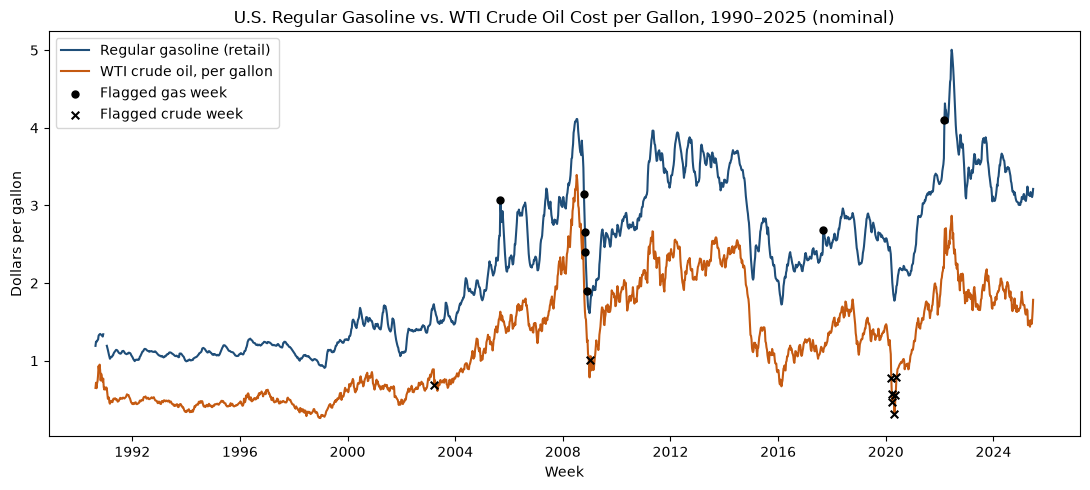

In [27]:
#chart of the cleaned series with the flagged weeks marked
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df.index, df["regular"], label="Regular gasoline (retail)", color="#1f4e79")
ax.plot(df.index, df["crude_gal"], label="WTI crude oil, per gallon", color="#c55a11")
fr = df[df["flag_regular_jump"]]
fc = df[df["flag_crude_jump"]]
ax.scatter(fr.index, fr["regular"], color="black", zorder=3, s=25, label="Flagged gas week")
ax.scatter(fc.index, fc["crude_gal"], color="black", marker="x", zorder=3, s=30, label="Flagged crude week")
ax.set_title("U.S. Regular Gasoline vs. WTI Crude Oil Cost per Gallon, 1990–2025 (nominal)")
ax.set_xlabel("Week")
ax.set_ylabel("Dollars per gallon")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "chart0_cleaned_series.png"), dpi=150)
plt.show()

Shows: regular gasoline and crude per gallon move together over 35 years, with the gas line consistently above the crude line. The gap is the spread. Flagged weeks fall on sharp turns: the 2008 crash, the 2020 crude collapse and the 2022 spike. The break in late 1990 is the six missing weeks. Hides: prices are nominal, so the rise since 2000 partly reflects inflation, and weekly noise makes it hard to see how quickly gas reacts to crude. That timing question is the focus of the analysis.

## Task 9: Validation Checks

In [28]:
checks = {
    "one row per Monday": df.index.is_unique and (df.index.dayofweek == 0).all(),
    "no gaps in the Monday calendar": len(pd.date_range(df.index.min(), df.index.max(), freq="W-MON")) == len(df),
    "all prices positive": df[["regular", "midgrade", "premium", "diesel", "crude_gal"]].min().min() > 0,
    "every gas week has crude": df.loc[df["regular"].notna(), "crude_gal"].notna().all(),
    "every week has CPI": df["cpi"].notna().all(),
    "premium >= regular": (df["premium"] >= df["regular"]).where(df["premium"].notna(), True).all(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

PASS  one row per Monday
PASS  no gaps in the Monday calendar
PASS  all prices positive
PASS  every gas week has crude
PASS  every week has CPI
PASS  premium >= regular


In [29]:
#spot check against a published EIA figure: record high for regular, week of June 13, 2022
print("Highest regular price:", df["regular"].max(), "on", df["regular"].idxmax().date())

Highest regular price: 5.006 on 2022-06-13


All checks pass. The highest regular price in the data is \$5.006 on June 13, 2022, which matches EIA's published record weekly average, confirming the copy of the data matches the original source.

## Task 10: Save the Processed Data

In [30]:
out = df.reset_index()
out["date"] = out["date"].dt.strftime("%Y-%m-%d")
out = out.round(4)
out.to_csv(os.path.join(PROCESSED, "weekly_prices.csv"), index=False)
out.to_csv(os.path.join(FRONTEND_DATA, "weekly_prices.csv"), index=False)   #copy for the website
print(out.columns.tolist())
print(f"{out.shape[0]} rows, {out.shape[1]} columns")

['date', 'regular', 'midgrade', 'premium', 'diesel', 'wti_bbl', 'crude_interpolated', 'crude_gal', 'cpi', 'regular_real', 'midgrade_real', 'premium_real', 'diesel_real', 'crude_gal_real', 'spread_regular', 'spread_regular_real', 'spread_midgrade', 'spread_midgrade_real', 'spread_premium', 'spread_premium_real', 'spread_diesel', 'spread_diesel_real', 'flag_regular_jump', 'flag_crude_jump']
1819 rows, 24 columns


### Data dictionary: `data/processed/weekly_prices.csv`

| Column | Description | Unit |
|---|---|---|
| `date` | Monday of the EIA survey week | YYYY-MM-DD |
| `regular`, `midgrade`, `premium`, `diesel` | U.S. average retail price, taxes included | nominal $/gallon |
| `wti_bbl` | Average WTI spot price of the previous trading week | nominal $/barrel |
| `crude_interpolated` | True if `wti_bbl` was filled by interpolation | boolean |
| `crude_gal` | `wti_bbl` ÷ 42 | nominal $/gallon |
| `cpi` | CPI-U for the week's month | index (1982–84 = 100) |
| `*_real` | Price in June 2025 dollars | real $/gallon |
| `spread_*` | Retail price minus `crude_gal` | nominal $/gallon |
| `spread_*_real` | Real retail price minus real `crude_gal` | real $/gallon |
| `flag_regular_jump`, `flag_crude_jump` | Week-to-week change has a robust z-score above 6 | boolean |

## Summary of Preprocessing Decisions

| Issue | Decision | Rows affected |
|---|---|---|
| Overlapping gas series | Kept the "all formulations" average for regular, midgrade and premium, and "all" diesel | 15 series → 4 |
| Six missing weeks (Dec 1990 – Jan 1991) | Left empty; not interpolated | 6 weeks |
| Midgrade, premium and diesel start in 1994 | Left empty (structural missingness) | 187–223 weeks per fuel |
| WTI price of -\$36.98 on 2020-04-20 | Treated as an outlier and set to missing before averaging | 1 day |
| Crude data missing for three single weeks in 1999 | Linear interpolation, limited to one-week gaps, marked in `crude_interpolated` | 3 weeks |
| Daily crude vs. Monday gas survey | Each Monday matched to the previous week's average crude price | all weeks |
| Barrels vs. gallons | Crude divided by 42 | all weeks |
| Inflation | All prices also given in June 2025 dollars using CPI-U | all weeks |
| Large weekly moves | Flagged with a robust z-score > 6 and kept, since all 15 match real events | 15 weeks |

**Final dataset:** 1,819 weeks (August 20, 1990 to June 23, 2025), 24 columns, saved to `data/processed/weekly_prices.csv`.

**Limitation:** the TidyTuesday copy ends in June 2025, and the dataset is national only, with no regional breakdown.